# Dataset v1 · YOLO11n baseline

## 1. Imports and configuration

In [13]:
from pathlib import Path
from time import perf_counter
import math
import random
import shutil
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image
import torch
import ultralytics
from ultralytics import YOLO
import yaml
from IPython.display import display

In [14]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

dataset_dir = project_root / "data" / "dataset_v1"
yolo_dir = dataset_dir / "yolo_dataset"
dataset_yaml = yolo_dir / "data.yaml"
weights_path = project_root / "notebooks" / "yolo11n.pt"

runs_dir = dataset_dir / "runs"
experiment_name = "exp_01_baseline"
run_dir = runs_dir / experiment_name

training_config = dict(epochs=50, imgsz=640, batch=4, device="cpu", workers=0, seed=42)
seed = training_config["seed"]

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
display(pd.Series({
    "Python": sys.version.split()[0],
    "PyTorch": torch.__version__,
    "Ultralytics": ultralytics.__version__,
    "CUDA available": torch.cuda.is_available(),
    **training_config,
}))

Python                3.12.0
PyTorch           2.15.0+cpu
Ultralytics          8.4.218
CUDA available         False
epochs                    50
imgsz                    640
batch                      4
device                   cpu
workers                    0
seed                      42
dtype: object

## 2. Dataset verification

Notebook 04 excluded ten positive images with missing annotations. The prepared dataset contains 190 images across the original splits. Keep image outputs local.

In [15]:
yaml_text = dataset_yaml.read_text(encoding="utf-8")
print(yaml_text)
dataset_config = yaml.safe_load(yaml_text)
assert Path(dataset_config["path"]).resolve() == yolo_dir.resolve()
assert dataset_config["names"] == {0: "license_plate"}

expected_counts = {"train": 158, "val": 17, "test": 15}
image_paths = {}
label_dirs = {}

for split in expected_counts:
    image_dir = yolo_dir / dataset_config[split]
    label_dirs[split] = yolo_dir / "labels" / split
    assert image_dir.is_dir() and label_dirs[split].is_dir()
    image_paths[split] = sorted(image_dir.glob("*.jpg"))

actual_counts = {split: len(paths) for split, paths in image_paths.items()}
display(pd.DataFrame({"expected": expected_counts, "actual": actual_counts}))
assert actual_counts == expected_counts

path: "C:/Users/aarish.tickoo/workspace/traffic-pii-masking/data/dataset_v1/yolo_dataset"
train: "images/train"
val: "images/val"
test: "images/test"
names:
  0: license_plate



,expected,actual
train,158,158
val,17,17
test,15,15


In [16]:
# From 02_POC.ipynb.
def yolo_to_xyxy(box, image_width, image_height):
    cx, cy, bw, bh = box
    cx *= image_width
    cy *= image_height
    bw *= image_width
    bh *= image_height
    return cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2


def load_ground_truth(label_path, image_size):
    annotations = []
    for line in label_path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            class_id, *box = map(float, line.split())
            annotations.append((int(class_id), yolo_to_xyxy(box, *image_size)))
    return annotations


def draw_box(ax, box, color, caption=None):
    x1, y1, x2, y2 = box
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                           edgecolor=color, facecolor="none", linewidth=2))
    if caption:
        ax.text(x1, y1, caption, color=color, fontsize=9, backgroundcolor="black")

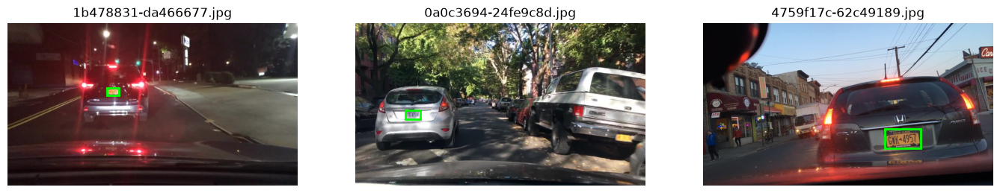

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, image_path in zip(axes, random.Random(seed).sample(image_paths["train"], 3)):
    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))
        label_path = label_dirs["train"] / f"{image_path.stem}.txt"
        for _, box in load_ground_truth(label_path, image.size):
            draw_box(ax, box, "lime")
    ax.set_title(image_path.name)
    ax.axis("off")
plt.show()

## 3. Model initialization

COCO pretraining gives YOLO11n useful visual features to fine-tune on this small licence plate dataset.

In [18]:
assert weights_path.is_file(), f"Expected COCO weights at {weights_path}"
model = YOLO(str(weights_path))
model.info(imgsz=training_config["imgsz"])

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


(181, 2624080, 0, 6.6733184)

## 4. Model training

Ultralytics writes label caches beside the labels and can repair JPEGs during verification. An experiment-local copy keeps those writes inside the run.

In [ ]:
run_dir.mkdir(parents=True, exist_ok=False)
experiment_dataset = run_dir / "dataset"

for split, paths in image_paths.items():
    image_dir = experiment_dataset / dataset_config[split]
    label_dir = experiment_dataset / "labels" / split
    image_dir.mkdir(parents=True)
    label_dir.mkdir(parents=True)

    for image_path in paths:
        shutil.copy2(image_path, image_dir / image_path.name)
        label_path = label_dirs[split] / f"{image_path.stem}.txt"
        shutil.copy2(label_path, label_dir / label_path.name)


FileExistsError: [WinError 183] Cannot create a file when that file already exists: 'c:\\Users\\aarish.tickoo\\workspace\\traffic-pii-masking\\data\\dataset_v1\\runs\\exp_01_baseline\\dataset\\images\\train'

In [23]:

experiment_yaml = experiment_dataset / "data.yaml"
experiment_config = {**dataset_config, "path": experiment_dataset.as_posix()}
experiment_yaml.write_text(yaml.safe_dump(experiment_config, sort_keys=False), encoding="utf-8")
print(experiment_yaml)

c:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\dataset\data.yaml


In [ ]:
# Reserve this training attempt before writing checkpoints.
(run_dir / "training_started").touch(exist_ok=False)

started_at = perf_counter()
training_results = model.train(
    data=str(experiment_yaml),
    project=str(runs_dir),
    name=experiment_name,
    exist_ok=True,
    save=True,
    plots=True,
    **training_config,
)
training_seconds = perf_counter() - started_at
print(f"Training duration: {training_seconds / 60:.2f} minutes")

Ultralytics 8.4.218  Python-3.12.0 torch-2.15.0+cpu CPU (12th Gen Intel Core i3-1215U)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\dataset\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=c:\Users\aarish.tickoo\workspace\traffi

In [3]:
runs_dir = Path.cwd().parent / "data" / "dataset_v1" / "runs"

checkpoints = list(runs_dir.rglob("last.pt"))
checkpoints

[WindowsPath('c:/Users/aarish.tickoo/workspace/traffic-pii-masking/data/dataset_v1/runs/exp_01_baseline/weights/last.pt')]

In [4]:
model = YOLO(str(checkpoints[0]))
model.train(resume=True)

Ultralytics 8.4.218  Python-3.12.0 torch-2.15.0+cpu CPU (12th Gen Intel Core i3-1215U)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\dataset\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=c:\Users\aarish.tickoo\workspace\traff

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000016B0F1794F0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

## 5. Training results and loss analysis

Box loss measures localization error. Classification loss measures class prediction error. Distribution focal loss trains the distributions used to estimate box edges.

Precision is the fraction of detections that are correct. Recall is the fraction of labelled plates detected. mAP50 summarizes precision and recall at IoU 0.50. mAP50–95 averages AP across IoU thresholds from 0.50 to 0.95.

In [7]:
history = pd.read_csv(run_dir / "results.csv")
history.columns = history.columns.str.strip()
print(history.columns.tolist())
display(history.tail())
print(f"Epochs completed: {len(history)}")

['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,2131.76,0.71460,0.43605,0.84855,0.83118,0.98534,0.96696,0.83118,0.73647,0.67921,0.78704,0.000218,0.000218,0.000218
46,47,2201.61,0.68199,0.43648,0.85460,0.86619,0.93333,0.97125,0.83215,0.74896,0.67894,0.78683,0.000178,0.000178,0.000178
47,48,2272.28,0.67073,0.41651,0.83080,1.00000,0.84802,0.97625,0.83977,0.75435,0.66377,0.78745,0.000139,0.000139,0.000139
48,49,2345.28,0.63979,0.40388,0.82506,0.88132,0.99068,0.97971,0.85328,0.74263,0.62848,0.78496,0.000099,0.000099,0.000099
49,50,2415.09,0.63582,0.39628,0.84473,0.88141,0.99146,0.97971,0.85328,0.74966,0.63068,0.78560,0.000060,0.000060,0.000060


Epochs completed: 50


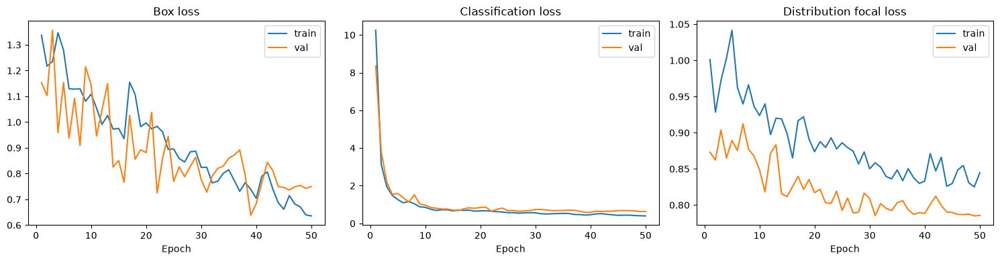

In [8]:
loss_names = {"box_loss": "Box loss", "cls_loss": "Classification loss",
              "dfl_loss": "Distribution focal loss"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (column, title) in zip(axes, loss_names.items()):
    for split in ["train", "val"]:
        ax.plot(history["epoch"], history[f"{split}/{column}"], label=split)
    ax.set(title=title, xlabel="Epoch")
    ax.legend()
fig.tight_layout()
plt.show()

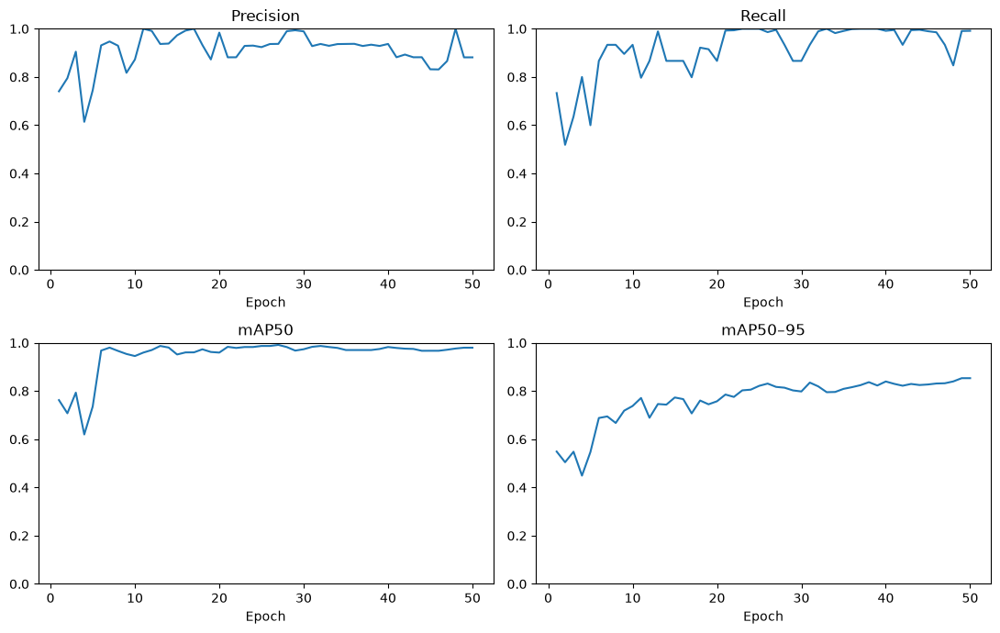

In [9]:
# Ultralytics computes its epoch-level detection metrics on validation.
metric_columns = {
    "metrics/precision(B)": "Precision", "metrics/recall(B)": "Recall",
    "metrics/mAP50(B)": "mAP50", "metrics/mAP50-95(B)": "mAP50–95",
}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (column, title) in zip(axes.flat, metric_columns.items()):
    ax.plot(history["epoch"], history[column])
    ax.set(title=title, xlabel="Epoch", ylim=(0, 1))
fig.tight_layout()
plt.show()

In [11]:
best_checkpoint = run_dir / "weights" / "best.pt"
assert best_checkpoint.is_file()
print(best_checkpoint)
best_model = YOLO(str(best_checkpoint))

c:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\weights\best.pt


## 6. Validation set evaluation

F1 is the harmonic mean of precision and recall. Ultralytics reports precision, recall, and F1 at its best-F1 point on the evaluated split. AP integrates performance across confidence scores.

In [24]:
evaluation_config = {
    key: training_config[key] for key in ("imgsz", "batch", "device", "workers")
}
validation = best_model.val(
    data=str(experiment_yaml), split="val", project=str(run_dir),
    name="validation", exist_ok=False, plots=True, **evaluation_config,
)

Ultralytics 8.4.218  Python-3.12.0 torch-2.15.0+cpu CPU (12th Gen Intel Core i3-1215U)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 116.2±36.8 MB/s, size: 67.4 KB)
val: Scanning C:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\dataset\labels\val.cache... 17 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.3it/s 1.2s0.4s
                   all         17         15      0.881      0.992       0.98      0.853
Speed: 1.0ms preprocess, 51.8ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to C:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\validation


Precision    0.881
Recall       0.992
F1           0.933
mAP50        0.980
mAP50–95     0.853
Name: Validation, dtype: float64

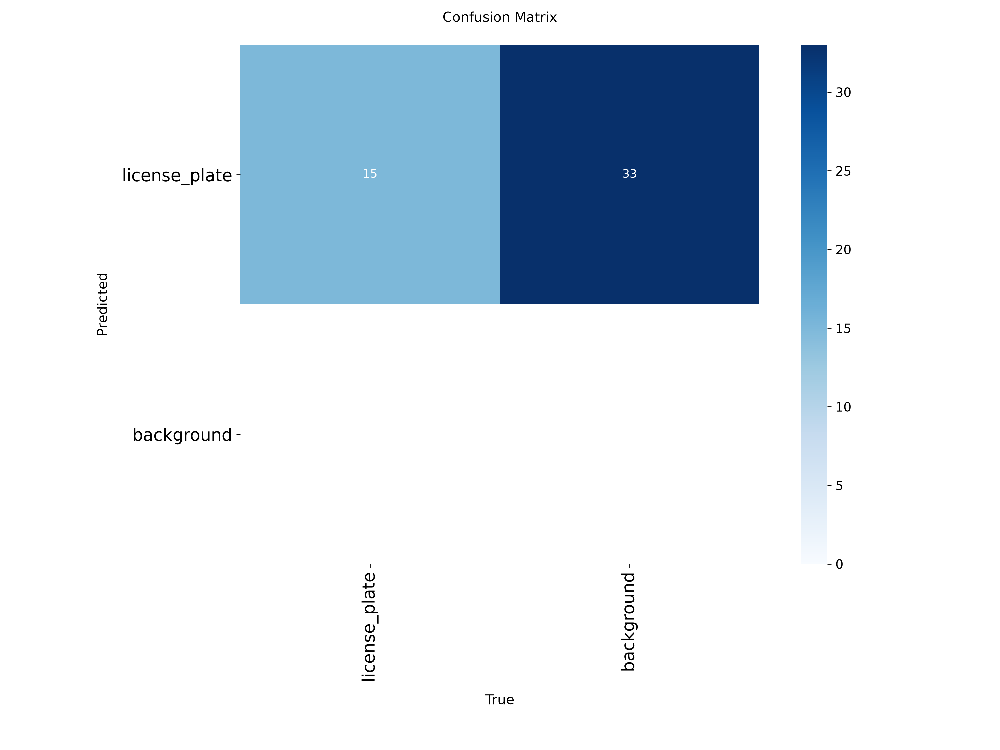

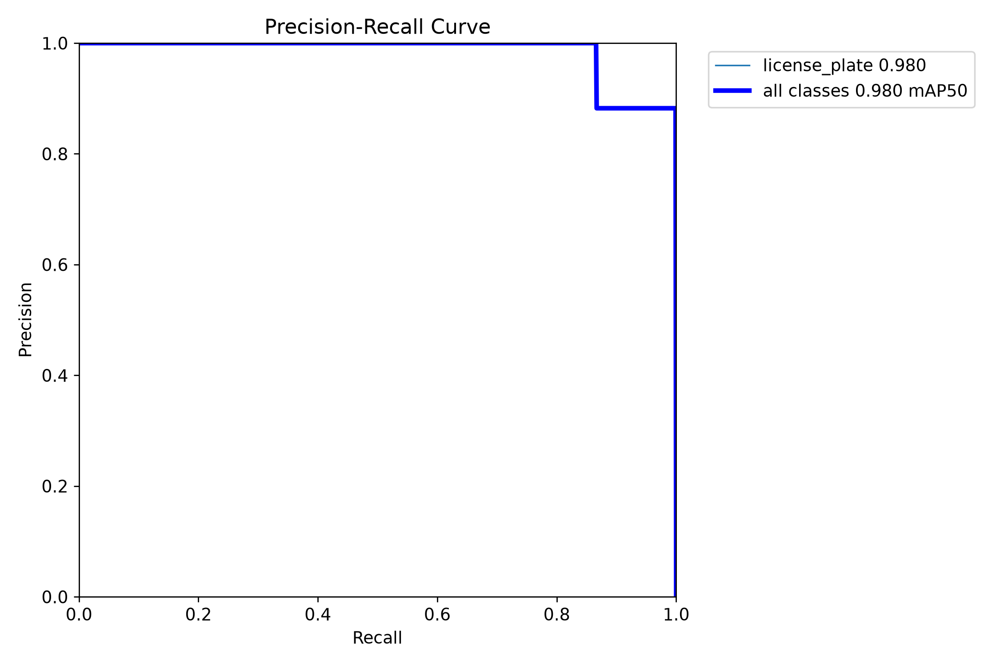

In [25]:
def detection_metrics(result):
    return {
        "Precision": float(result.box.mp),
        "Recall": float(result.box.mr),
        "F1": float(np.mean(result.box.f1)) if len(result.box.f1) else 0.0,
        "mAP50": float(result.box.map50),
        "mAP50–95": float(result.box.map),
    }


validation_scores = detection_metrics(validation)
display(pd.Series(validation_scores, name="Validation").round(3))

for artifact in [validation.save_dir / "confusion_matrix.png",
                 validation.save_dir / "BoxPR_curve.png"]:
    with Image.open(artifact) as plot:
        display(plot.copy())

## 7. Select a confidence threshold on validation

A lower threshold generally catches more plates and may mask more unrelated regions. Missing a readable plate carries the greater privacy cost. Choose the threshold that maximizes validation F2, which weights recall more heavily than precision. The interpolated curves give a provisional operating point for this small split.

In [26]:
curves = {y_label: (x, values)
          for x, values, x_label, y_label in validation.curves_results
          if x_label == "Confidence" and y_label in {"Precision", "Recall"}}
thresholds, precision = curves["Precision"]
_, recall = curves["Recall"]

confidence_table = pd.DataFrame({
    "confidence": thresholds, "precision": precision[0], "recall": recall[0],
}).query("confidence >= 0.001")
denominator = 4 * confidence_table["precision"] + confidence_table["recall"]
confidence_table["F2"] = (
    5 * confidence_table["precision"] * confidence_table["recall"]
    / denominator.replace(0, np.nan)
).fillna(0)

# Favor higher recall and lower confidence when F2 is tied.
operating_point = confidence_table.sort_values(
    ["F2", "recall", "confidence"], ascending=[False, False, True]
).iloc[0]
selected_confidence = float(operating_point["confidence"])
display(operating_point.round(4))

confidence    0.0711
precision     0.8823
recall        0.9999
F2            0.9739
Name: 71, dtype: float64

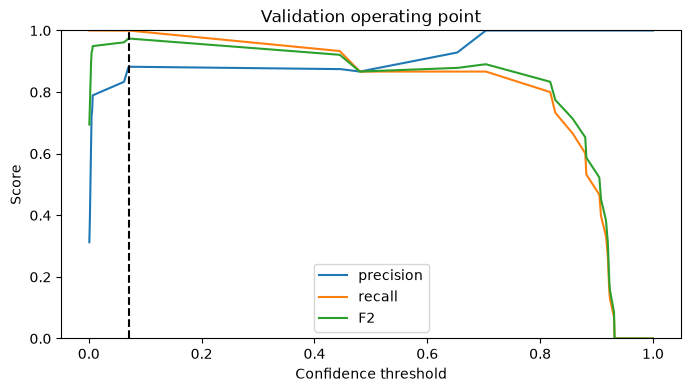

In [27]:
ax = confidence_table.plot(x="confidence", y=["precision", "recall", "F2"],
                           figsize=(8, 4), ylim=(0, 1))
ax.axvline(selected_confidence, color="black", linestyle="--")
ax.set(xlabel="Confidence threshold", ylabel="Score", title="Validation operating point")
plt.show()

## 8. Held-out test evaluation

The standard metrics describe the test split. Inference and error analysis use the threshold fixed on validation.

In [28]:
test_evaluation = best_model.val(
    data=str(experiment_yaml), split="test", project=str(run_dir),
    name="test", exist_ok=False, plots=False, **evaluation_config,
)
test_scores = detection_metrics(test_evaluation)
display(pd.Series(test_scores, name="Test (standard metrics)").round(3))

Ultralytics 8.4.218  Python-3.12.0 torch-2.15.0+cpu CPU (12th Gen Intel Core i3-1215U)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 5.5±2.7 MB/s, size: 62.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\dataset\labels\test... 15 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 206.8it/s 0.1s
val: New cache created: C:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.8it/s 1.0s0.4s
                   all         15         16      0.931      0.938      0.966      0.782
Speed: 1.4ms preprocess, 55.9ms infere

Precision    0.931
Recall       0.938
F1           0.934
mAP50        0.966
mAP50–95     0.782
Name: Test (standard metrics), dtype: float64

In [29]:
test_image_dir = experiment_dataset / dataset_config["test"]
test_results = best_model.predict(
    source=str(test_image_dir), imgsz=training_config["imgsz"],
    device=training_config["device"], batch=1,
    conf=selected_confidence, iou=0.7, verbose=False, save=False,
)
assert {Path(result.path).name for result in test_results} == {
    path.name for path in image_paths["test"]
}
print(f"Predicted on {len(test_results)} held-out images")

latency = pd.DataFrame([result.speed for result in test_results])
display(latency.agg(["mean", "median"]).round(2))

Predicted on 15 held-out images


,preprocess,inference,postprocess
mean,2.00,62.03,1.45
median,1.52,59.32,1.24


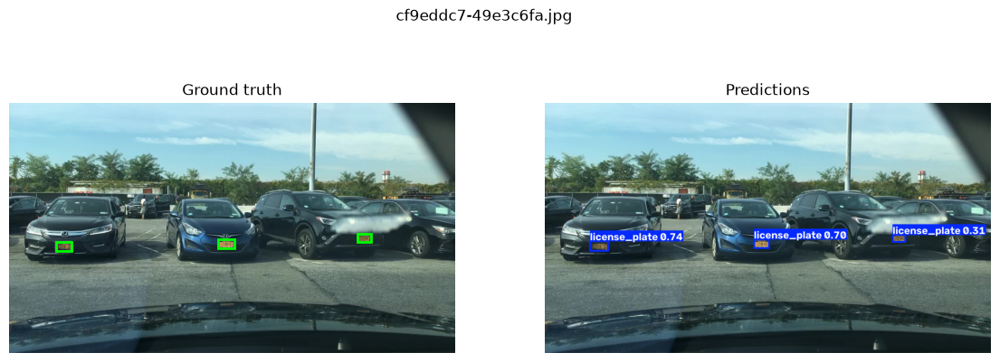

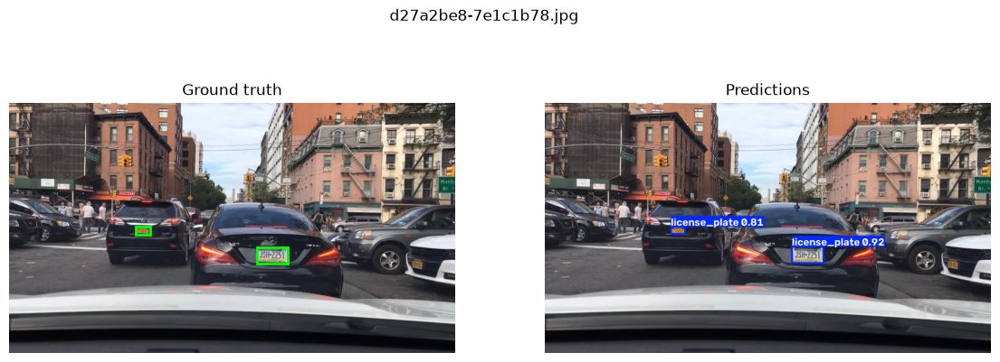

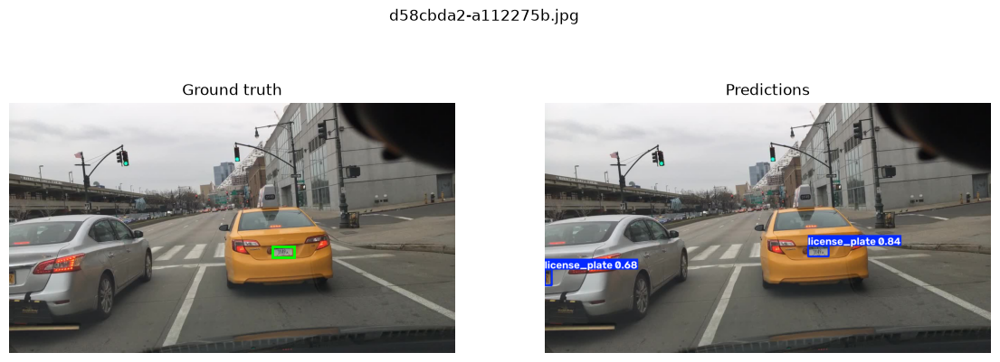

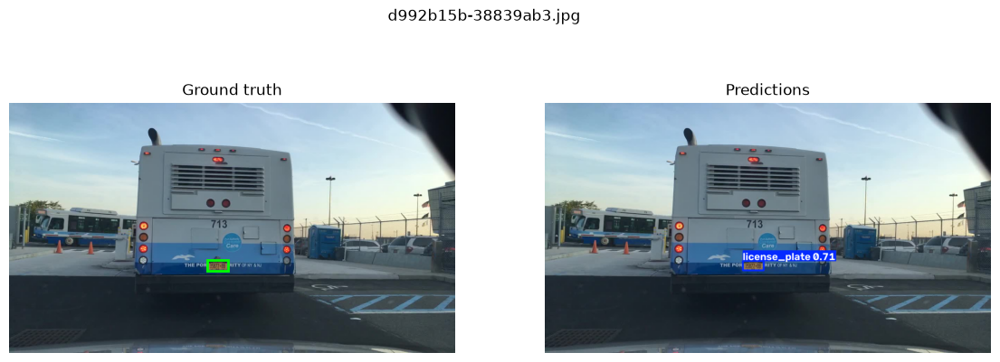

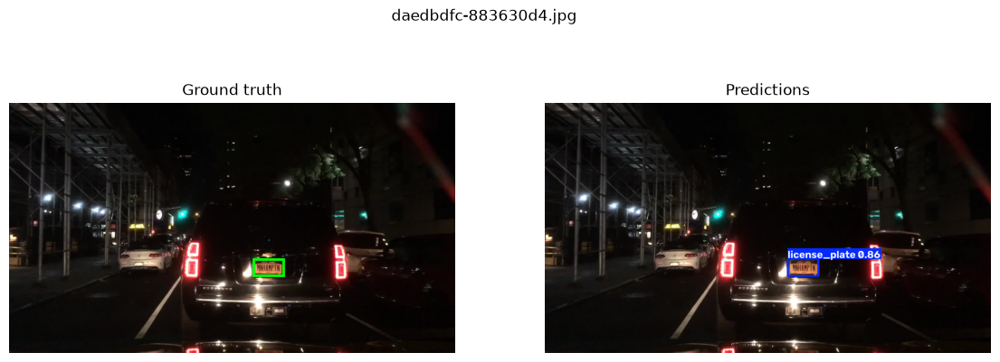

...

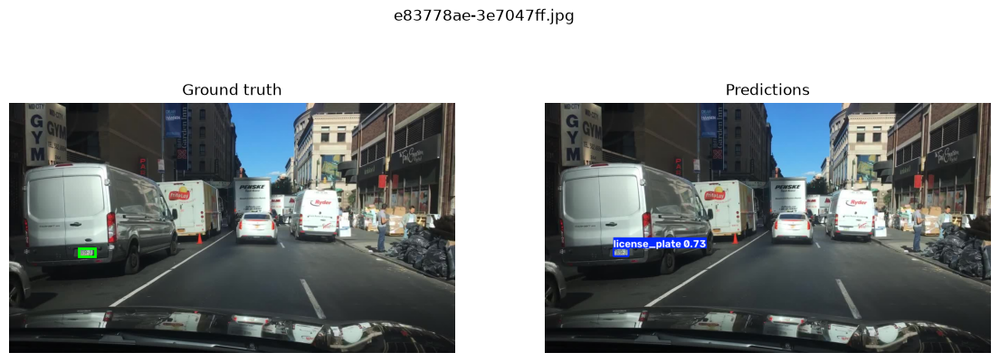

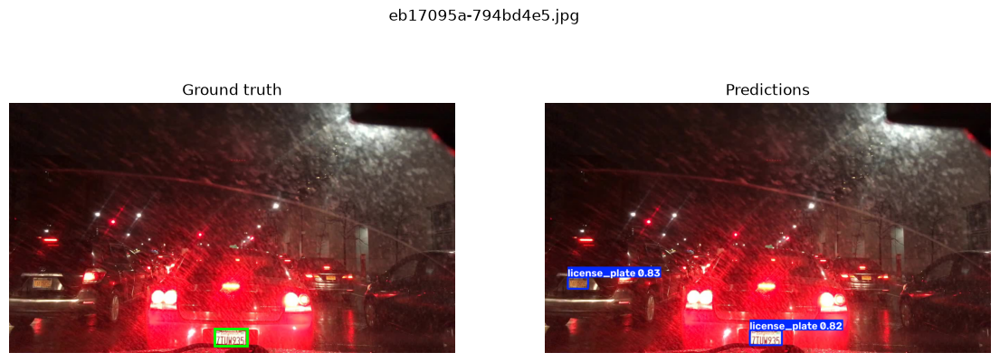

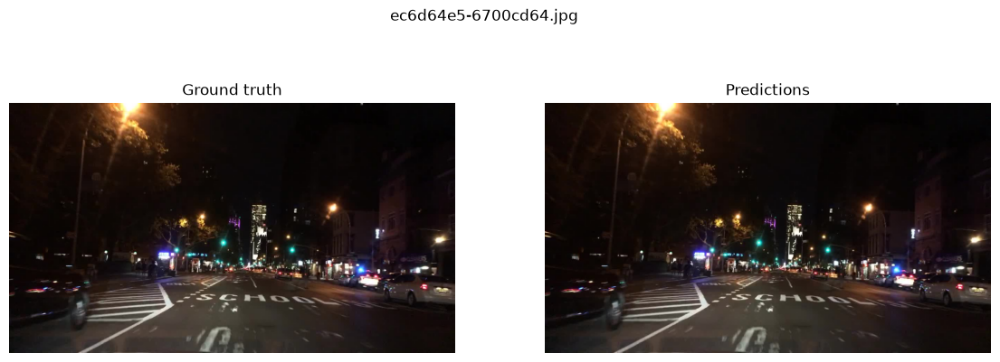

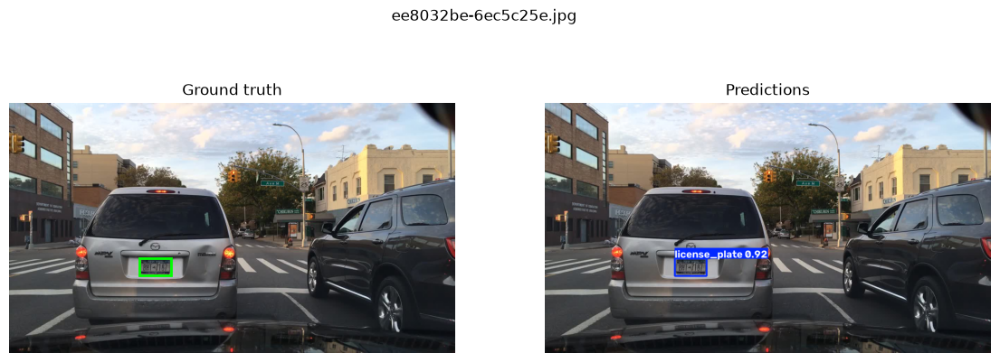

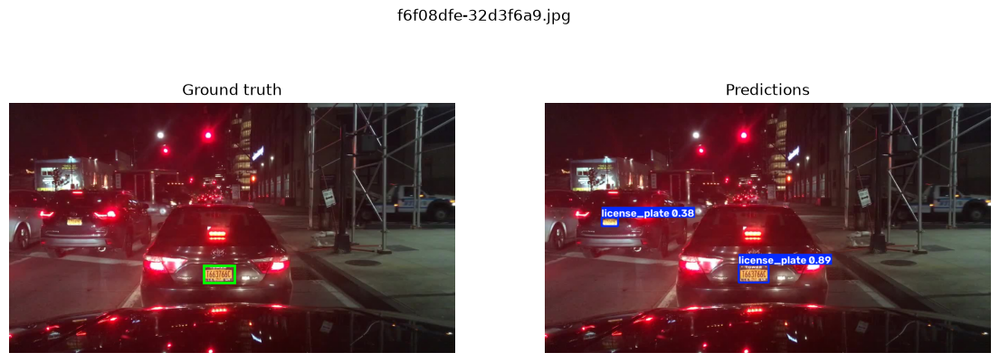

In [30]:
ground_truth = {}
for result in test_results:
    image_id = Path(result.path).name
    height, width = result.orig_shape
    label_path = experiment_dataset / "labels" / "test" / f"{Path(image_id).stem}.txt"
    ground_truth[image_id] = load_ground_truth(label_path, (width, height))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].imshow(result.orig_img[:, :, ::-1])
    for _, box in ground_truth[image_id]:
        draw_box(axes[0], box, "lime")
    axes[1].imshow(result.plot(conf=True)[:, :, ::-1])
    axes[0].set_title("Ground truth")
    axes[1].set_title("Predictions")
    fig.suptitle(image_id)
    for ax in axes:
        ax.axis("off")
    plt.show()

## 9. Error analysis at IoU 0.50

Match predictions in descending confidence order to the available ground-truth box of the same class with the highest IoU. After true positives are assigned, pair remaining overlapping boxes to find localization errors. Each such pair also counts as one false positive and one false negative.

In [31]:
def box_iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b
    intersection = (max(0, min(ax2, bx2) - max(ax1, bx1))
                    * max(0, min(ay2, by2) - max(ay1, by1)))
    union = (ax2 - ax1) * (ay2 - ay1) + (bx2 - bx1) * (by2 - by1) - intersection
    return intersection / union if union > 0 else 0.0


def best_target(class_id, box, targets, available):
    candidates = [(box_iou(box, targets[i][1]), i)
                  for i in sorted(available) if targets[i][0] == class_id]
    return max(candidates, default=(0.0, None))

In [32]:
iou_threshold = 0.5
error_records = []
results_by_name = {Path(result.path).name: result for result in test_results}

for image_id, result in results_by_name.items():
    targets = ground_truth[image_id]
    predictions = sorted(
        zip(result.boxes.cls.tolist(), result.boxes.xyxy.tolist(), result.boxes.conf.tolist()),
        key=lambda prediction: prediction[2], reverse=True,
    )
    available = set(range(len(targets)))
    unmatched = []

    for class_id, box, confidence in predictions:
        overlap, index = best_target(class_id, box, targets, available)
        if overlap >= iou_threshold:
            available.remove(index)
            error_records.append((image_id, "TP", box, targets[index][1], confidence, overlap))
        else:
            unmatched.append((class_id, box, confidence))

    localized = set()
    for class_id, box, confidence in unmatched:
        error_records.append((image_id, "FP", box, None, confidence, None))
        overlap, index = best_target(class_id, box, targets, available - localized)
        if 0 < overlap < iou_threshold:
            localized.add(index)
            error_records.append((image_id, "Poor localization", box, targets[index][1], confidence, overlap))

    for index in sorted(available):
        error_records.append((image_id, "FN", None, targets[index][1], None, None))

In [33]:
errors = pd.DataFrame(error_records, columns=[
    "image_id", "outcome", "prediction", "ground_truth", "confidence", "IoU",
])
outcomes = ["TP", "FP", "FN", "Poor localization"]
error_counts = errors["outcome"].value_counts().reindex(outcomes, fill_value=0)
display(error_counts.rename("count"))
display(errors.head())

tp, fp, fn = (int(error_counts[label]) for label in ["TP", "FP", "FN"])
test_at_threshold = {
    "Precision": tp / (tp + fp) if tp + fp else 0.0,
    "Recall": tp / (tp + fn) if tp + fn else 0.0,
    "F1": 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0,
}
display(pd.Series(test_at_threshold, name="Test at selected confidence").round(3))

outcome
TP                   16
FP                    4
FN                    0
Poor localization     0
Name: count, dtype: int64

,image_id,outcome,prediction,ground_truth,confidence,IoU
0,cf9eddc7-49e3c6fa.jpg,TP,"[130.783661, 398.474915, 182.063568, 426.067566]","(133.32992, 399.99996, 178.3296, 425.82996)",0.742618,0.821473
1,cf9eddc7-49e3c6fa.jpg,TP,"[600.461304, 393.654358, 643.861084, 418.52594]","(600.0, 391.66992, 644.99968, 419.1696)",0.701063,0.872276
2,cf9eddc7-49e3c6fa.jpg,TP,"[998.413574, 380.518616, 1034.634277, 400.570251]","(999.16992, 376.67016, 1037.49952, 400.83048)",0.308132,0.755527
3,d27a2be8-7e1c1b78.jpg,TP,"[709.767944, 413.330017, 799.84436, 461.861267]","(709.99936, 415.00044, 798.3296, 461.67012)",0.921068,0.943000
4,d27a2be8-7e1c1b78.jpg,TP,"[362.175018, 356.446808, 402.456146, 377.666595]","(361.66976, 355.83012, 403.32992, 379.17036)",0.814454,0.879056


Precision    0.800
Recall       1.000
F1           0.889
Name: Test at selected confidence, dtype: float64

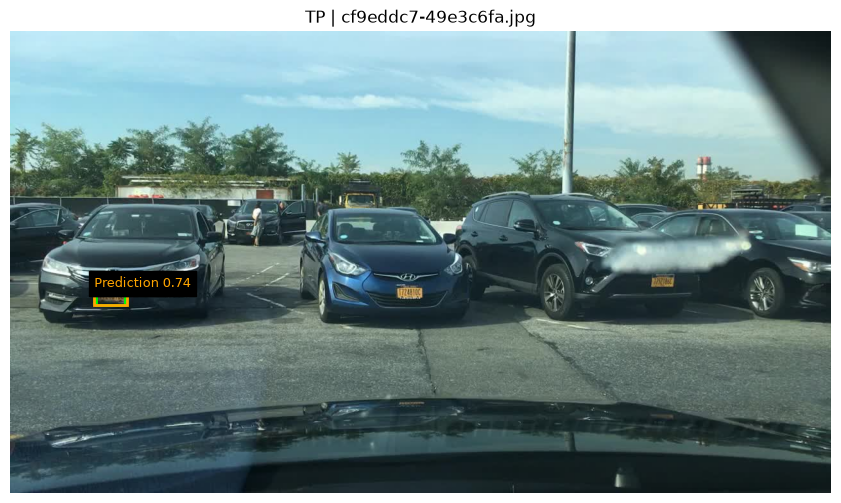

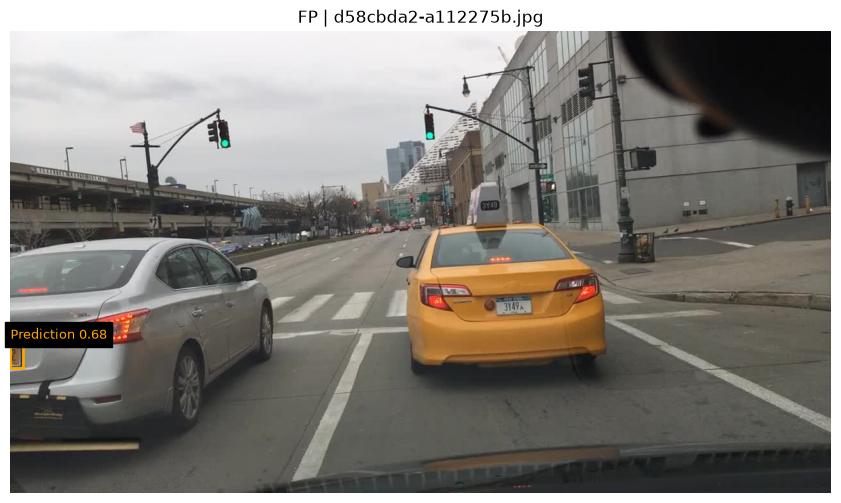

No FN examples
No Poor localization examples


In [34]:
for outcome in outcomes:
    examples = errors.loc[errors["outcome"] == outcome]
    if examples.empty:
        print(f"No {outcome} examples")
        continue

    example = examples.iloc[0]
    result = results_by_name[example["image_id"]]
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.imshow(result.orig_img[:, :, ::-1])
    if example["ground_truth"] is not None:
        draw_box(ax, example["ground_truth"], "lime", "Ground truth")
    if example["prediction"] is not None:
        draw_box(ax, example["prediction"], "orange", f"Prediction {example['confidence']:.2f}")
    ax.set_title(f"{outcome} | {example['image_id']}")
    ax.axis("off")
    plt.show()

## 10. Licence plate anonymization

Reuse the test predictions and cover each detected plate with black pixels. Review the resulting images for any plates the detector missed.

In [35]:
# Adapted from 02_POC.ipynb. Round outward to cover the predicted box.
def mask_license_plates(image, boxes):
    masked_image = image.copy()
    height, width = image.shape[:2]

    for x1, y1, x2, y2 in boxes:
        left, right = np.clip([math.floor(x1), math.ceil(x2)], 0, width)
        top, bottom = np.clip([math.floor(y1), math.ceil(y2)], 0, height)
        masked_image[top:bottom, left:right] = 0

    return masked_image

In [36]:
anonymized_dir = run_dir / "anonymized"
anonymized_dir.mkdir(exist_ok=False)
masked_images = {}

for result in test_results:
    image_id = Path(result.path).name
    masked = mask_license_plates(result.orig_img, result.boxes.xyxy.tolist())
    masked_images[image_id] = masked
    Image.fromarray(masked[:, :, ::-1]).save(anonymized_dir / f"{Path(image_id).stem}.png")

print(f"Saved {len(masked_images)} masked images to {anonymized_dir}")

Saved 15 masked images to c:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\dataset_v1\runs\exp_01_baseline\anonymized


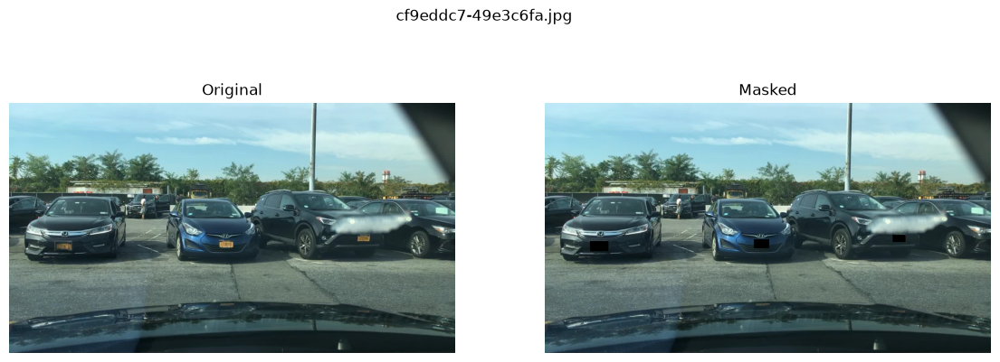

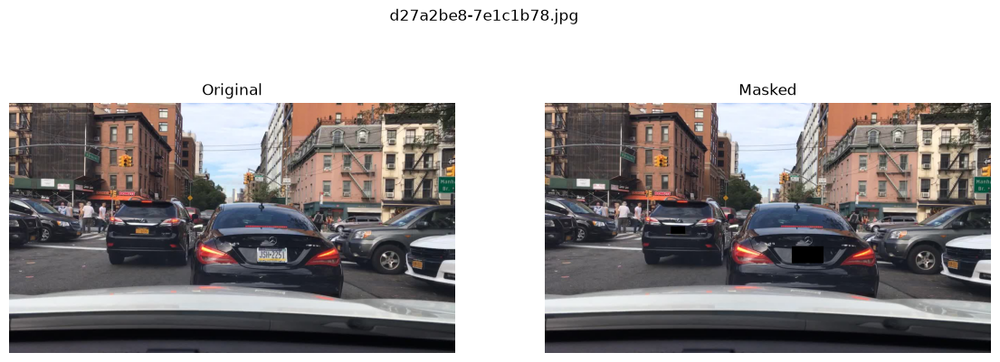

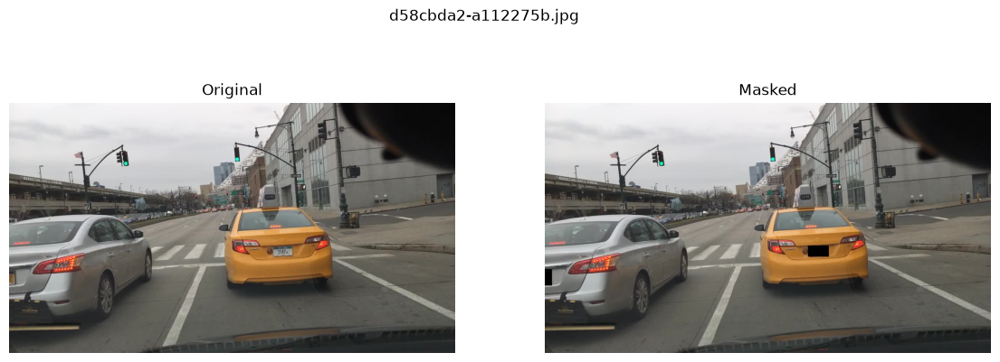

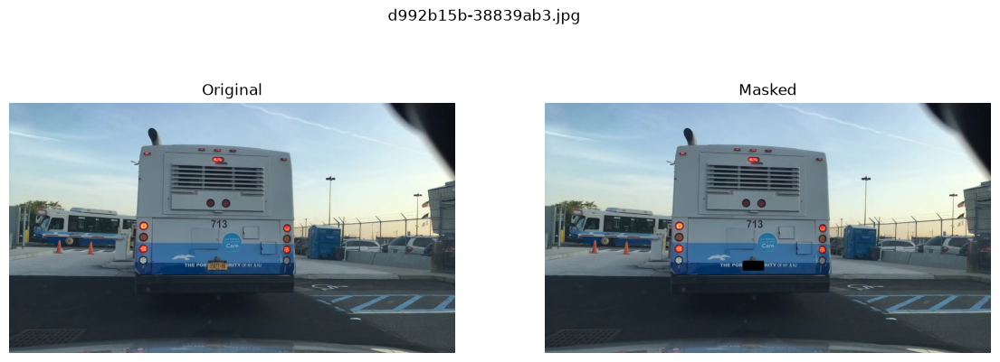

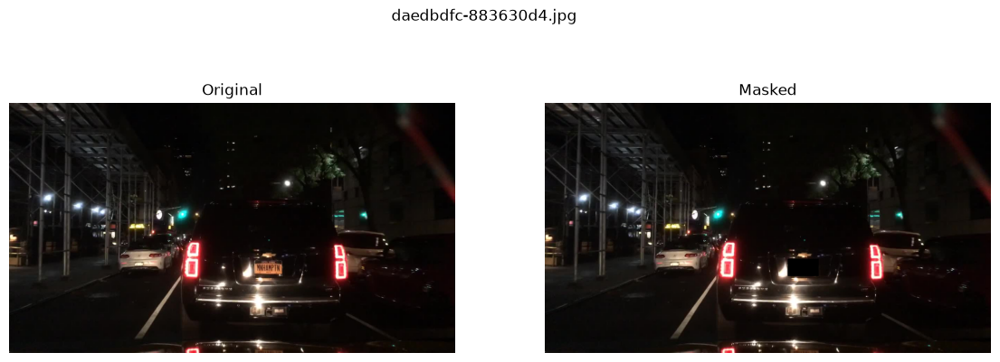

...

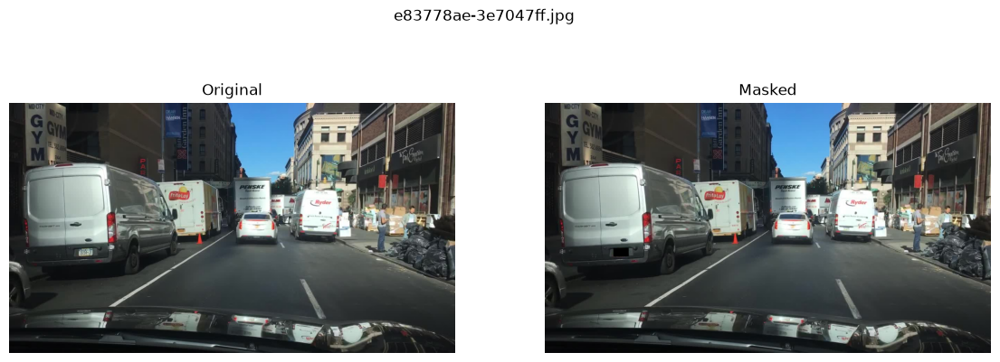

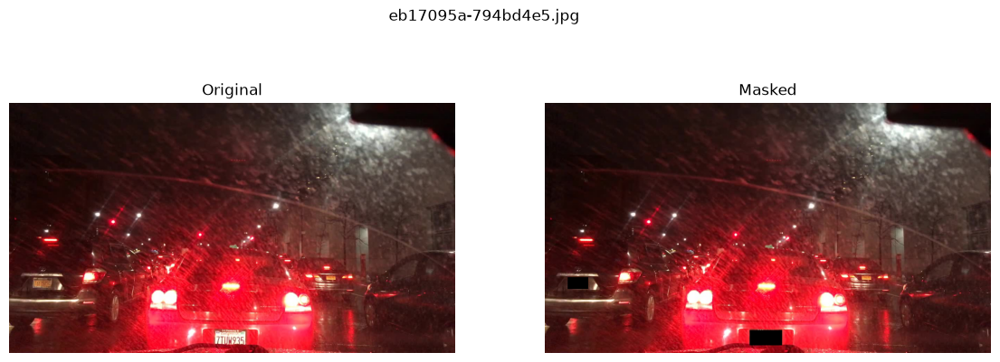

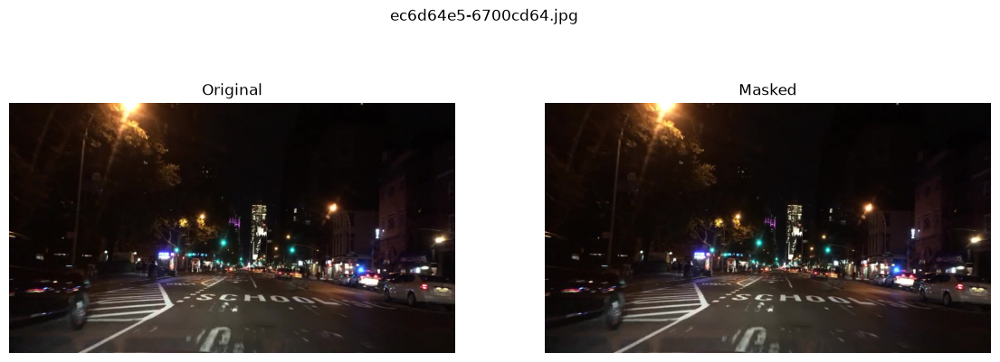

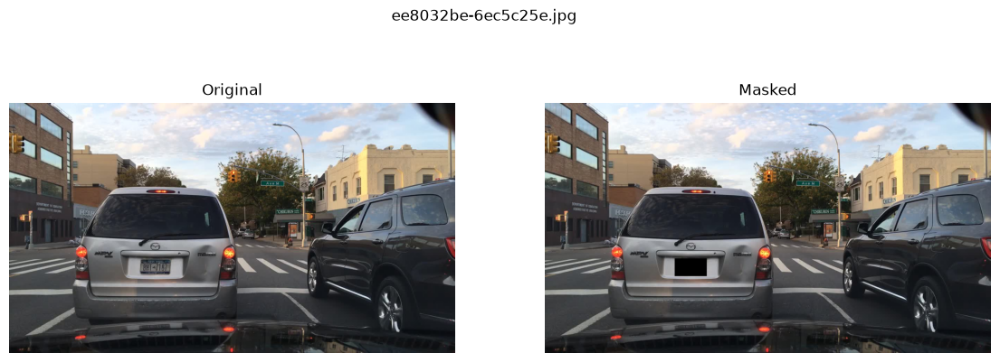

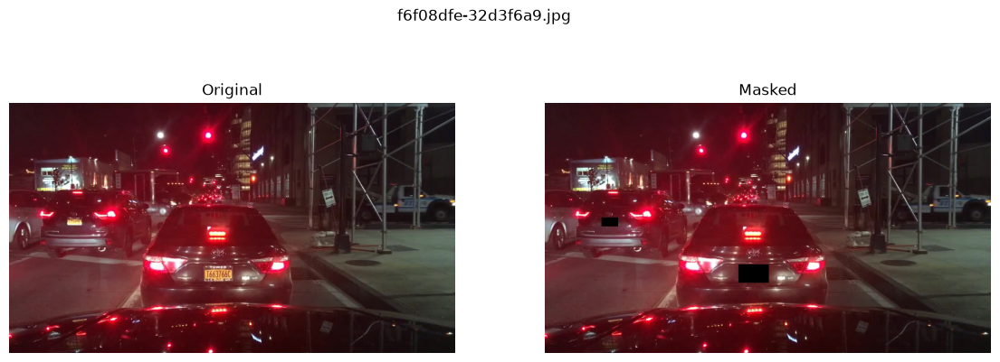

In [37]:
for image_id, masked in masked_images.items():
    original = results_by_name[image_id].orig_img
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, image, title in zip(axes, [original, masked], ["Original", "Masked"]):
        ax.imshow(image[:, :, ::-1])
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(image_id)
    plt.show()

## 11. Experiment summary

Ultralytics reports per-image forward-pass latency. The stage total adds preprocessing and postprocessing.

In [39]:
display(pd.Series({
    "Model": "YOLO11n",
    "Pretrained weights": weights_path.name,
    "Dataset": f"v1 ({actual_counts})",
    "Experiment": experiment_name,
    **training_config,
    "Actual epochs completed": len(history),
    # "Training duration (min)": round(training_seconds / 60, 2),
    "Best checkpoint": str(best_checkpoint.relative_to(project_root)),
    "Selected confidence": round(selected_confidence, 4),
    "Mean CPU inference (ms/image)": round(latency["inference"].mean(), 2),
    "Mean CPU stage total (ms/image)": round(latency.sum(axis=1).mean(), 2),
}))
display(pd.DataFrame({
    "Validation (standard)": validation_scores,
    "Test (standard)": test_scores,
    "Test (selected confidence)": test_at_threshold,
}).round(3).fillna("—"))

Model                                                                        YOLO11n
Pretrained weights                                                        yolo11n.pt
Dataset                                   v1 ({'train': 158, 'val': 17, 'test': 15})
Experiment                                                           exp_01_baseline
epochs                                                                            50
imgsz                                                                            640
batch                                                                              4
device                                                                           cpu
workers                                                                            0
seed                                                                              42
Actual epochs completed                                                           50
Best checkpoint                    data\dataset_v1\runs\exp_01_ba

C:\Users\aarish.tickoo\AppData\Local\Temp\ipykernel_13636\2627528673.py:18: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  }).round(3).fillna("—"))


,Validation (standard),Test (standard),Test (selected confidence)
Precision,0.881,0.931,0.8
Recall,0.992,0.938,1.0
F1,0.933,0.934,0.889
mAP50,0.980,0.966,—
mAP50–95,0.853,0.782,—


## 12. Freeze the evaluated Model V1

Run the final cell on its own to archive the checkpoint and operating point. It uses the saved evaluation results.

In [1]:
# Run this cell independently to archive the evaluated checkpoint.
import hashlib
import json
from pathlib import Path
from shutil import copyfile
from tempfile import TemporaryDirectory

root = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "notebooks/05_model_v1_training.ipynb").is_file())
checkpoint = root / "data/dataset_v1/runs/exp_01_baseline/weights/best.pt"
frozen = root / "models/model_v1"
expected_sha256 = "29363dc8319f3bf2f784a24af92fc228dfe20dd15a9a7e558294cf4436f2a00d"

def sha256(path: Path) -> str:
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

# Section 7 selected grid index 71 on np.linspace(0, 1, 1000).
# Section 11 preserves the reported metrics at three decimal places.
baseline = {
    "model": "YOLO11n V1",
    "source": checkpoint.relative_to(root).as_posix(),
    "sha256": expected_sha256,
    "confidence": 71 * (1 / 999),
    "confidence_selection": "Validation F2 maximum, grid index 71 (section 7)",
    "metrics_source": "05_model_v1_training.ipynb, section 11 (reported precision)",
    "validation_standard": dict(precision=0.881, recall=0.992, f1=0.933, map50=0.980, map50_95=0.853),
    "test_standard": dict(precision=0.931, recall=0.938, f1=0.934, map50=0.966, map50_95=0.782),
    "test_selected_confidence": dict(precision=0.8, recall=1.0, f1=0.889, match_iou=0.5),
    "imgsz": 640,
    "nms_iou": 0.7,
}

if frozen.exists():
    if (sha256(frozen / "best.pt") != expected_sha256
            or json.loads((frozen / "baseline.json").read_text()) != baseline):
        raise RuntimeError(f"Existing baseline differs from the evaluated V1: {frozen}")
else:
    if sha256(checkpoint) != expected_sha256:
        raise RuntimeError("Checkpoint differs from the evaluated V1.")
    frozen.parent.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=frozen.parent) as staging:
        pending = Path(staging) / "model_v1"
        pending.mkdir()
        copyfile(checkpoint, pending / "best.pt")
        if sha256(pending / "best.pt") != expected_sha256:
            raise RuntimeError("Copied checkpoint failed checksum verification.")
        (pending / "baseline.json").write_text(json.dumps(baseline, indent=2) + "\n")
        pending.rename(frozen)

print(f"Verified frozen V1: {frozen}")

Verified frozen V1: /Users/aarishtickoo/workspace/traffic-pii-masking/models/model_v1
